# TelcoPeople — Modélisation avancée et validation temporelle

Ce notebook améliore la baseline CatBoost précédente en respectant la chronologie réelle du challenge.

**Baseline à battre :**
- F1 temporel : **0,3058**
- AUC temporelle : **0,7103**
- Seuil : **0,54**

Les améliorations testées sont :
1. variables salariales relatives au poste, au département et au grade ;
2. interactions entre engagement, salaire et absentéisme ;
3. tendances d’absentéisme donnant plus de poids aux mois récents ;
4. validation sur plusieurs fenêtres temporelles ;
5. comparaison de plusieurs configurations CatBoost ;
6. sélection d’un seuil plus robuste à partir des différentes validations.

## 1. Importation des bibliothèques

Cette cellule importe les outils nécessaires pour préparer les données, entraîner les modèles et mesurer le F1-score.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from catboost import CatBoostClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

Le notebook doit être placé dans le dossier `notebooks`. Les fichiers CSV sont lus depuis `data/raw`.

In [2]:
CHEMIN_DONNEES = "../data/raw/"

train = pd.read_csv(CHEMIN_DONNEES + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN_DONNEES + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)
print("Taux global de départ :", round(train["target"].mean(), 4))

Train : (5444, 42)
Test : (1507, 41)
Taux global de départ : 0.1014


## 3. Fonction de préparation avancée

La fonction nettoie les catégories et construit les variables de la baseline, puis ajoute des interactions métier. Les moyennes de groupe sont calculées sans utiliser la cible, donc elles ne provoquent pas de fuite directe de `target`.

In [3]:
def preparer_donnees_avancees(df):
    df = df.copy()

    # Nettoyage des catégories
    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = (
        df["departement"].fillna("INCONNU").str.strip().str.upper()
        .str.replace("DEPT", "DEP", regex=False)
    )
    df["contrat"] = (
        df["contrat"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(".", "", regex=False)
    )
    df["niveau_etude"] = (
        df["niveau_etude"].fillna("INCONNU").str.strip().str.upper()
        .str.replace(" ", "", regex=False)
        .str.replace("BAC2", "BAC+2", regex=False)
    )

    for colonne in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[colonne] = df[colonne].fillna("INCONNU").astype(str).str.strip().str.upper()

    # Conversion des dates
    colonnes_dates = [
        "date_reference", "date_naissance", "date_embauche",
        "date_derniere_promotion", "date_derniere_absence"
    ]
    for colonne in colonnes_dates:
        df[colonne] = pd.to_datetime(
            df[colonne], format="mixed", dayfirst=True, errors="coerce"
        )

    # Conversion du salaire
    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str)
        .str.replace("FCFA", "", regex=False)
        .str.replace(" ", "", regex=False),
        errors="coerce"
    )

    # Variables temporelles
    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (
        df["date_reference"] - df["date_derniere_promotion"]
    ).dt.days / 365.25
    df["jours_depuis_absence"] = (
        df["date_reference"] - df["date_derniere_absence"]
    ).dt.days
    df["annee_reference"] = df["date_reference"].dt.year
    df["mois_reference"] = df["date_reference"].dt.month

    # Indicateurs de valeurs manquantes et anomalies
    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_recente_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_actuel_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["engagement_precedent_manquant"] = df["engagement_precedent"].isna().astype(int)
    df["performance_actuelle_manquante"] = df["performance_actuelle"].isna().astype(int)
    df["performance_precedente_manquante"] = df["performance_precedente"].isna().astype(int)
    df["salaire_12m_manquant"] = df["salaire_12m_avant"].isna().astype(int)
    df["anciennete_invalide"] = (df["anciennete"] < 0).astype(int)

    # Variables salariales principales
    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = (
        df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)
    )
    df["salaire_anormal"] = (
        (df["salaire_mensuel"] <= 0) |
        (df["ratio_salaire_reference"] < 0.5) |
        (df["ratio_salaire_reference"] > 2)
    ).astype(int)

    # Position salariale dans les groupes, calculée à la date de référence
    groupes = {
        "poste": ["date_reference", "poste"],
        "departement": ["date_reference", "departement"],
        "grade": ["date_reference", "grade"]
    }
    for nom, cles in groupes.items():
        moyenne = df.groupby(cles)["salaire_mensuel"].transform("median")
        df[f"ratio_salaire_{nom}"] = df["salaire_mensuel"] / moyenne.replace(0, np.nan)
        df[f"ecart_salaire_{nom}"] = df["salaire_mensuel"] - moyenne

    # Engagement et performance
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]
    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)

    # Absentéisme cumulé
    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)

    # Les mois les plus récents reçoivent plus de poids
    poids = {1: 6, 2: 5, 3: 4, 4: 3, 5: 2, 6: 1}
    df["jours_abs_ponderes"] = sum(df[f"jours_abs_m{i}"] * poids[i] for i in range(1, 7))
    df["nb_abs_ponderes"] = sum(df[f"nb_abs_m{i}"] * poids[i] for i in range(1, 7))
    df["abs_non_just_ponderees"] = sum(df[f"abs_non_just_m{i}"] * poids[i] for i in range(1, 7))

    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    # Interactions métier
    df["engagement_x_ratio_salaire"] = df["engagement_actuel"] * df["ratio_salaire_reference"]
    df["engagement_x_absence"] = df["engagement_actuel"] * df["jours_abs_6m"]
    df["faible_engagement"] = (df["engagement_actuel"] < 3).astype(int)
    df["salaire_sous_reference"] = (df["ratio_salaire_reference"] < 1).astype(int)
    df["absenteisme_eleve"] = (df["jours_abs_6m"] > 2).astype(int)
    df["risque_engagement_salaire"] = (
        (df["faible_engagement"] == 1) &
        (df["salaire_sous_reference"] == 1)
    ).astype(int)
    df["risque_engagement_absence"] = (
        (df["faible_engagement"] == 1) &
        (df["absenteisme_eleve"] == 1)
    ).astype(int)
    df["risque_combine"] = (
        (df["faible_engagement"] == 1) &
        (df["salaire_sous_reference"] == 1) &
        (df["absenteisme_eleve"] == 1)
    ).astype(int)

    return df

## 4. Préparation simultanée du train et du test

Pour que les médianes de groupe soient cohérentes entre toutes les périodes, le train et le test sont temporairement regroupés avant l’application de la fonction. La cible n’est jamais utilisée dans ces calculs.

In [4]:
train_sans_cible = train.drop(columns="target").copy()
train_sans_cible["origine"] = "train"
test_temporaire = test.copy()
test_temporaire["origine"] = "test"

donnees_combinees = pd.concat([train_sans_cible, test_temporaire], ignore_index=True)
donnees_preparees = preparer_donnees_avancees(donnees_combinees)

train_prepare = donnees_preparees.loc[
    donnees_preparees["origine"] == "train"
].drop(columns="origine").reset_index(drop=True)

test_prepare = donnees_preparees.loc[
    donnees_preparees["origine"] == "test"
].drop(columns="origine").reset_index(drop=True)

train_prepare["target"] = train["target"].values

print("Train préparé :", train_prepare.shape)
print("Test préparé :", test_prepare.shape)

Train préparé : (5444, 88)
Test préparé : (1507, 87)


## 5. Contrôle des nouvelles variables

Cette cellule vérifie que les variables avancées sont bien créées et qu’aucune valeur infinie n’est conservée.

In [5]:
train_prepare = train_prepare.replace([np.inf, -np.inf], np.nan)
test_prepare = test_prepare.replace([np.inf, -np.inf], np.nan)

nouvelles_variables = [
    "ratio_salaire_poste", "ratio_salaire_departement", "ratio_salaire_grade",
    "engagement_moyen", "jours_abs_ponderes", "tendance_absence",
    "risque_engagement_salaire", "risque_engagement_absence", "risque_combine"
]

display(train_prepare[nouvelles_variables].describe().T)

,count,mean,std,min,25%,50%,75%,max
ratio_salaire_poste,5443.0,1.087833,0.540656,0.00,0.873418,1.000000,1.229885,13.356164
ratio_salaire_departement,5443.0,1.265553,0.967879,0.00,0.737566,1.000000,1.474999,30.314961
ratio_salaire_grade,5443.0,1.025912,0.498421,0.00,0.889908,1.000000,1.115385,12.631579
engagement_moyen,4952.0,3.542387,0.674459,1.21,3.081726,3.547861,4.016675,5.000000
jours_abs_ponderes,5444.0,6.275716,14.671497,0.00,0.000000,0.000000,8.000000,274.000000
tendance_absence,5444.0,0.294269,2.181991,-6.00,0.000000,0.000000,0.000000,45.000000
risque_engagement_salaire,5444.0,0.121234,0.326429,0.00,0.000000,0.000000,0.000000,1.000000
risque_engagement_absence,5444.0,0.058597,0.234890,0.00,0.000000,0.000000,0.000000,1.000000
risque_combine,5444.0,0.038207,0.191714,0.00,0.000000,0.000000,0.000000,1.000000


## 6. Préparation des variables explicatives

Les dates brutes et l’identifiant sont retirés. Les durées et composantes temporelles créées précédemment restent disponibles pour le modèle.

In [6]:
colonnes_a_retirer = [
    "target", "id", "date_reference", "date_naissance",
    "date_embauche", "date_derniere_promotion", "date_derniere_absence"
]

X = train_prepare.drop(columns=colonnes_a_retirer)
y = train_prepare["target"]

X_test = test_prepare.drop(columns=[
    "id", "date_reference", "date_naissance",
    "date_embauche", "date_derniere_promotion", "date_derniere_absence"
])

print("X :", X.shape)
print("X_test :", X_test.shape)
print("Colonnes identiques :", list(X.columns) == list(X_test.columns))

X : (5444, 81)
X_test : (1507, 81)
Colonnes identiques : True


## 7. Définition des fenêtres temporelles

Trois validations sont utilisées. Chaque modèle apprend uniquement sur les périodes antérieures à la période validée. Cela permet d’évaluer la stabilité du modèle dans le temps.

In [7]:
periodes_validation = [
    pd.Timestamp("2023-06-30"),
    pd.Timestamp("2023-12-31"),
    pd.Timestamp("2024-06-30")
]

print("Fenêtres de validation :")
for periode in periodes_validation:
    nombre_train = (train_prepare["date_reference"] < periode).sum()
    nombre_validation = (train_prepare["date_reference"] == periode).sum()
    print(periode.date(), "| train :", nombre_train, "| validation :", nombre_validation)

Fenêtres de validation :
2023-06-30 | train : 1858 | validation : 1083
2023-12-31 | train : 2941 | validation : 1189
2024-06-30 | train : 4130 | validation : 1314


## 8. Configurations CatBoost à comparer

Trois configurations sont testées. Elles restent volontairement raisonnables pour limiter le temps de calcul et le surapprentissage.

In [8]:
configurations = {
    "catboost_d5": {
        "depth": 5,
        "learning_rate": 0.03,
        "l2_leaf_reg": 5
    },
    "catboost_d6": {
        "depth": 6,
        "learning_rate": 0.03,
        "l2_leaf_reg": 7
    },
    "catboost_d7": {
        "depth": 7,
        "learning_rate": 0.025,
        "l2_leaf_reg": 10
    }
}

configurations

{'catboost_d5': {'depth': 5, 'learning_rate': 0.03, 'l2_leaf_reg': 5},
 'catboost_d6': {'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 7},
 'catboost_d7': {'depth': 7, 'learning_rate': 0.025, 'l2_leaf_reg': 10}}

## 9. Fonction d’évaluation temporelle

Pour chaque période, la fonction entraîne un modèle, prédit les probabilités et recherche le meilleur seuil F1. Les prédictions de toutes les fenêtres sont conservées afin de construire ensuite un seuil global plus robuste.

In [9]:
def evaluer_configuration(nom_configuration, parametres):
    resultats = []
    predictions_hors_temps = []
    modeles = []

    for periode in periodes_validation:
        masque_train = train_prepare["date_reference"] < periode
        masque_validation = train_prepare["date_reference"] == periode

        X_train_fold = X.loc[masque_train].copy()
        y_train_fold = y.loc[masque_train].copy()
        X_validation_fold = X.loc[masque_validation].copy()
        y_validation_fold = y.loc[masque_validation].copy()

        colonnes_categorielles = X_train_fold.select_dtypes(
            include=["object", "string"]
        ).columns.tolist()

        modele = CatBoostClassifier(
            iterations=1500,
            loss_function="Logloss",
            eval_metric="AUC",
            auto_class_weights="Balanced",
            random_seed=42,
            verbose=False,
            **parametres
        )

        modele.fit(
            X_train_fold,
            y_train_fold,
            cat_features=colonnes_categorielles,
            eval_set=(X_validation_fold, y_validation_fold),
            early_stopping_rounds=150
        )

        probabilites = modele.predict_proba(X_validation_fold)[:, 1]

        scores_seuils = []
        for seuil in np.arange(0.20, 0.81, 0.01):
            predictions = (probabilites >= seuil).astype(int)
            scores_seuils.append((f1_score(y_validation_fold, predictions), seuil))

        meilleur_f1, meilleur_seuil = max(scores_seuils)
        predictions = (probabilites >= meilleur_seuil).astype(int)

        resultats.append({
            "configuration": nom_configuration,
            "periode": str(periode.date()),
            "taille_train": len(X_train_fold),
            "taille_validation": len(X_validation_fold),
            "iteration": modele.get_best_iteration(),
            "auc": roc_auc_score(y_validation_fold, probabilites),
            "seuil_local": meilleur_seuil,
            "f1_local": meilleur_f1,
            "precision_locale": precision_score(y_validation_fold, predictions, zero_division=0),
            "rappel_local": recall_score(y_validation_fold, predictions, zero_division=0)
        })

        predictions_hors_temps.append(pd.DataFrame({
            "index": X_validation_fold.index,
            "periode": periode,
            "y_reel": y_validation_fold.values,
            "probabilite": probabilites
        }))
        modeles.append(modele)

    return pd.DataFrame(resultats), pd.concat(predictions_hors_temps), modeles

## 10. Exécution des expériences

Cette cellule entraîne les trois configurations sur les trois fenêtres. Le calcul peut prendre quelques minutes.

In [10]:
resultats_tous = []
predictions_toutes = {}
modeles_tous = {}

for nom_configuration, parametres in configurations.items():
    print("Évaluation de", nom_configuration)
    resultats, predictions, modeles = evaluer_configuration(
        nom_configuration, parametres
    )
    resultats_tous.append(resultats)
    predictions_toutes[nom_configuration] = predictions
    modeles_tous[nom_configuration] = modeles

resultats_tous = pd.concat(resultats_tous, ignore_index=True)
display(resultats_tous)

Évaluation de catboost_d5
Évaluation de catboost_d6
Évaluation de catboost_d7


,configuration,periode,taille_train,taille_validation,iteration,auc,seuil_local,f1_local,precision_locale,rappel_local
0,catboost_d5,2023-06-30,1858,1083,77,0.673413,0.63,0.263415,0.272727,0.254717
1,catboost_d5,2023-12-31,2941,1189,125,0.715770,0.58,0.327586,0.261468,0.438462
2,catboost_d5,2024-06-30,4130,1314,306,0.710712,0.58,0.312329,0.241525,0.441860
3,catboost_d6,2023-06-30,1858,1083,37,0.676136,0.55,0.263959,0.180556,0.490566
4,catboost_d6,2023-12-31,2941,1189,166,0.719271,0.56,0.327273,0.247059,0.484615
5,catboost_d6,2024-06-30,4130,1314,182,0.714624,0.60,0.318043,0.262626,0.403101
6,catboost_d7,2023-06-30,1858,1083,5,0.676880,0.51,0.267003,0.182131,0.500000
7,catboost_d7,2023-12-31,2941,1189,112,0.718900,0.57,0.328446,0.265403,0.430769
8,catboost_d7,2024-06-30,4130,1314,145,0.712642,0.56,0.298077,0.216028,0.480620


## 11. Comparaison des configurations

Le classement repose d’abord sur le F1 moyen, puis sur l’AUC moyenne. L’écart-type du F1 permet de vérifier la stabilité temporelle.

In [11]:
resume_configurations = resultats_tous.groupby("configuration").agg(
    f1_moyen=("f1_local", "mean"),
    f1_ecart_type=("f1_local", "std"),
    auc_moyenne=("auc", "mean"),
    precision_moyenne=("precision_locale", "mean"),
    rappel_moyen=("rappel_local", "mean"),
    iteration_mediane=("iteration", "median")
).sort_values(["f1_moyen", "auc_moyenne"], ascending=False)

display(resume_configurations)

meilleure_configuration = resume_configurations.index[0]
print("Meilleure configuration :", meilleure_configuration)

,f1_moyen,f1_ecart_type,auc_moyenne,precision_moyenne,rappel_moyen,iteration_mediane
configuration,,,,,,
catboost_d6,0.303092,0.034202,0.703344,0.230080,0.459427,166.0
catboost_d5,0.301110,0.033525,0.699965,0.258574,0.378346,125.0
catboost_d7,0.297842,0.030722,0.702807,0.221187,0.470463,112.0


Meilleure configuration : catboost_d6


## 12. Recherche d’un seuil global robuste

Au lieu de choisir uniquement le seuil optimal de juin 2024, les prédictions des trois périodes sont regroupées. Le seuil retenu optimise le F1 global hors temps.

In [12]:
predictions_selectionnees = predictions_toutes[meilleure_configuration].copy()

resultats_seuil_global = []
for seuil in np.arange(0.20, 0.81, 0.01):
    predictions = (
        predictions_selectionnees["probabilite"] >= seuil
    ).astype(int)

    resultats_seuil_global.append({
        "seuil": round(float(seuil), 2),
        "f1": f1_score(predictions_selectionnees["y_reel"], predictions),
        "precision": precision_score(predictions_selectionnees["y_reel"], predictions, zero_division=0),
        "rappel": recall_score(predictions_selectionnees["y_reel"], predictions, zero_division=0)
    })

resultats_seuil_global = pd.DataFrame(resultats_seuil_global)
meilleure_ligne = resultats_seuil_global.loc[resultats_seuil_global["f1"].idxmax()]
seuil_global = float(meilleure_ligne["seuil"])

print("Seuil global :", seuil_global)
print("F1 global hors temps :", round(meilleure_ligne["f1"], 4))
print("Précision globale :", round(meilleure_ligne["precision"], 4))
print("Rappel global :", round(meilleure_ligne["rappel"], 4))

display(resultats_seuil_global.sort_values("f1", ascending=False).head(10))

Seuil global : 0.6
F1 global hors temps : 0.2981
Précision globale : 0.2727
Rappel global : 0.3288


,seuil,f1,precision,rappel
40,0.60,0.298137,0.272727,0.328767
37,0.57,0.297872,0.224860,0.441096
36,0.56,0.294970,0.214109,0.473973
35,0.55,0.293695,0.207207,0.504110
39,0.59,0.291807,0.247148,0.356164
38,0.58,0.290650,0.231018,0.391781
34,0.54,0.284866,0.195320,0.526027
30,0.50,0.282098,0.180835,0.641096
33,0.53,0.279525,0.187617,0.547945
41,0.61,0.278689,0.277929,0.279452


## 13. Visualisation de la stabilité temporelle

Le graphique compare le F1 obtenu par chaque configuration sur chaque période de validation.

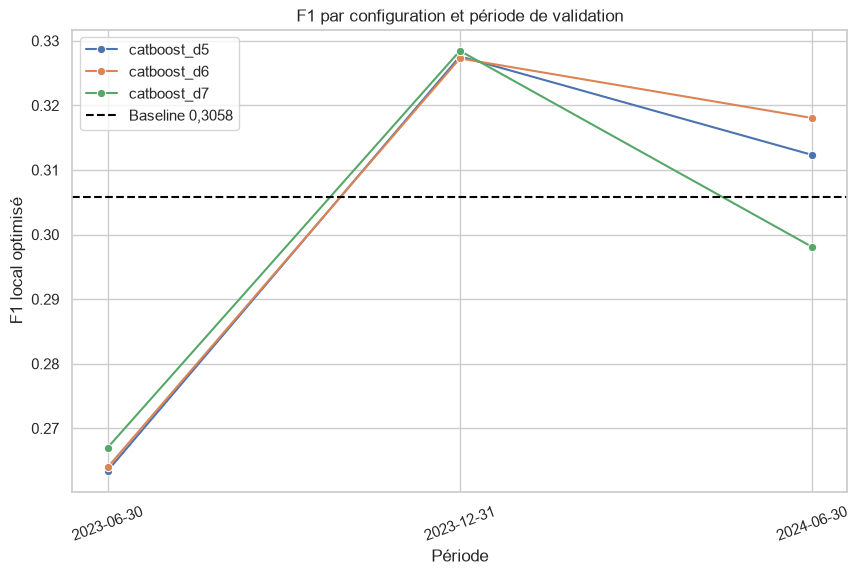

In [13]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=resultats_tous,
    x="periode",
    y="f1_local",
    hue="configuration",
    marker="o"
)
plt.axhline(0.3058, color="black", linestyle="--", label="Baseline 0,3058")
plt.title("F1 par configuration et période de validation")
plt.xlabel("Période")
plt.ylabel("F1 local optimisé")
plt.xticks(rotation=20)
plt.legend()
plt.show()

## 14. Évaluation détaillée sur juin 2024

Cette période est la plus proche du test final. Elle donne une estimation directement comparable à la baseline précédente.

              precision    recall  f1-score   support

           0     0.9310    0.8768    0.9031      1185
           1     0.2626    0.4031    0.3180       129

    accuracy                         0.8303      1314
   macro avg     0.5968    0.6399    0.6106      1314
weighted avg     0.8654    0.8303    0.8456      1314

AUC juin 2024 : 0.7146


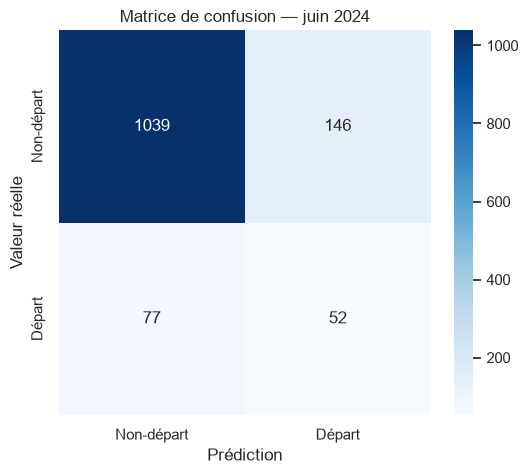

In [14]:
predictions_2024 = predictions_selectionnees.loc[
    predictions_selectionnees["periode"] == pd.Timestamp("2024-06-30")
].copy()

predictions_2024["prediction"] = (
    predictions_2024["probabilite"] >= seuil_global
).astype(int)

print(classification_report(
    predictions_2024["y_reel"],
    predictions_2024["prediction"],
    digits=4
))

print("AUC juin 2024 :", round(roc_auc_score(
    predictions_2024["y_reel"], predictions_2024["probabilite"]
), 4))

matrice = confusion_matrix(
    predictions_2024["y_reel"], predictions_2024["prediction"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    matrice, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Non-départ", "Départ"],
    yticklabels=["Non-départ", "Départ"]
)
plt.title("Matrice de confusion — juin 2024")
plt.xlabel("Prédiction")
plt.ylabel("Valeur réelle")
plt.show()

## 15. Importance des variables

Le dernier modèle temporel de la meilleure configuration est utilisé pour examiner les variables les plus importantes.

,variable,importance
73,engagement_x_ratio_salaire,12.524443
62,engagement_moyen,6.464401
12,engagement_actuel,4.420042
58,ratio_salaire_grade,4.198143
50,ecart_salaire_reference,3.725453
49,ratio_salaire_reference,3.499139
63,performance_moyenne,3.025111
36,anciennete,2.687028
35,age,2.649779
11,performance_precedente,2.558412


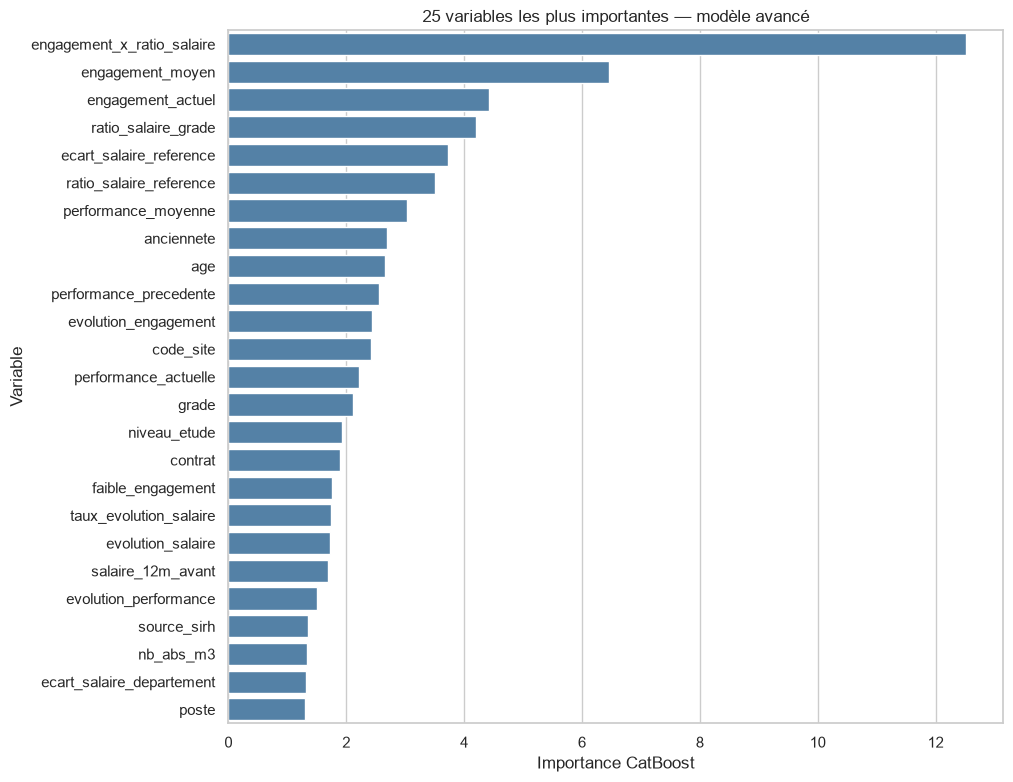

In [15]:
modele_dernier_fold = modeles_tous[meilleure_configuration][-1]

importance = pd.DataFrame({
    "variable": X.columns,
    "importance": modele_dernier_fold.get_feature_importance()
}).sort_values("importance", ascending=False)

display(importance.head(30))

plt.figure(figsize=(10, 9))
sns.barplot(
    data=importance.head(25),
    x="importance",
    y="variable",
    color="steelblue"
)
plt.title("25 variables les plus importantes — modèle avancé")
plt.xlabel("Importance CatBoost")
plt.ylabel("Variable")
plt.show()

## 16. Réentraînement final sur toutes les données

La meilleure configuration est réentraînée sur les cinq périodes historiques. Le nombre d’itérations est fixé à la médiane des meilleures itérations temporelles.

In [16]:
parametres_finaux = configurations[meilleure_configuration].copy()
iterations_finales = int(max(
    50,
    resume_configurations.loc[meilleure_configuration, "iteration_mediane"] + 1
))

colonnes_categorielles = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

modele_final = CatBoostClassifier(
    iterations=iterations_finales,
    loss_function="Logloss",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=100,
    **parametres_finaux
)

modele_final.fit(
    X,
    y,
    cat_features=colonnes_categorielles
)

print("Configuration finale :", meilleure_configuration)
print("Nombre d'itérations :", iterations_finales)

0:	learn: 0.6895753	total: 53.8ms	remaining: 8.93s
100:	learn: 0.5701770	total: 4.31s	remaining: 2.82s
166:	learn: 0.5431297	total: 6.99s	remaining: 0us
Configuration finale : catboost_d6
Nombre d'itérations : 167


## 17. Création des soumissions

Deux soumissions sont produites :
- une avec le seuil global robuste ;
- une avec un seuil légèrement plus strict, utile pour diversifier les cinq soumissions quotidiennes.

In [17]:
probabilites_test = modele_final.predict_proba(X_test)[:, 1]

seuil_strict = min(seuil_global + 0.05, 0.90)

soumission_globale = pd.DataFrame({
    "id": test_prepare["id"],
    "prediction": (probabilites_test >= seuil_global).astype(int)
})

soumission_stricte = pd.DataFrame({
    "id": test_prepare["id"],
    "prediction": (probabilites_test >= seuil_strict).astype(int)
})

chemin_global = "../submissions/submission_catboost_avance_seuil_global.csv"
chemin_strict = "../submissions/submission_catboost_avance_seuil_strict.csv"

soumission_globale.to_csv(chemin_global, index=False)
soumission_stricte.to_csv(chemin_strict, index=False)

print("Soumission globale :", chemin_global)
print("Seuil :", seuil_global)
print("Départs prédits :", soumission_globale["prediction"].sum())
print("Taux prédit :", round(soumission_globale["prediction"].mean() * 100, 2), "%")

print("\nSoumission stricte :", chemin_strict)
print("Seuil :", round(seuil_strict, 2))
print("Départs prédits :", soumission_stricte["prediction"].sum())
print("Taux prédit :", round(soumission_stricte["prediction"].mean() * 100, 2), "%")

Soumission globale : ../submissions/submission_catboost_avance_seuil_global.csv
Seuil : 0.6
Départs prédits : 253
Taux prédit : 16.79 %

Soumission stricte : ../submissions/submission_catboost_avance_seuil_strict.csv
Seuil : 0.65
Départs prédits : 132
Taux prédit : 8.76 %


## 18. Journal des expériences

Le journal conserve les résultats des configurations et les paramètres de la solution finale. Il facilite la comparaison avec les futures expériences et les scores du leaderboard.

In [18]:
resultats_tous.to_csv(
    "../reports/resultats_validations_temporelles_v2.csv",
    index=False
)

journal_final = pd.DataFrame([{
    "experience": "CatBoost avancé multi-fenêtres v2",
    "configuration": meilleure_configuration,
    "nombre_variables": X.shape[1],
    "f1_moyen_fenetres": resume_configurations.loc[meilleure_configuration, "f1_moyen"],
    "auc_moyenne_fenetres": resume_configurations.loc[meilleure_configuration, "auc_moyenne"],
    "seuil_global": seuil_global,
    "iterations_finales": iterations_finales,
    "positifs_test_seuil_global": int(soumission_globale["prediction"].sum()),
    "positifs_test_seuil_strict": int(soumission_stricte["prediction"].sum())
}])

journal_final.to_csv(
    "../reports/journal_modelisation_avancee_v2.csv",
    index=False
)

display(journal_final.T)

,0
experience,CatBoost avancé multi-fenêtres v2
configuration,catboost_d6
nombre_variables,81
f1_moyen_fenetres,0.303092
auc_moyenne_fenetres,0.703344
seuil_global,0.6
iterations_finales,167
positifs_test_seuil_global,253
positifs_test_seuil_strict,132


## Conclusion

Ce notebook remplace la validation unique par une validation temporelle multi-fenêtres et ajoute des variables métier avancées. La comparaison finale doit porter sur :

- le F1 moyen sur les trois périodes ;
- le F1 de juin 2024 au seuil global ;
- la stabilité entre les périodes ;
- le score obtenu par chaque soumission sur le leaderboard.

Une amélioration réelle doit augmenter le score sans dépendre d’une seule période ou d’un seuil très instable.